# setup

In [1]:
# Tìm thư mục gốc của dự án để notebook biết nơi chứa mã nguồn và dữ liệu.
from pathlib import Path
import sys
import pandas as pd

# Find repository root by searching upward for `src` and `configs` folders
def find_project_root(max_up=6):
    p = Path.cwd()
    for _ in range(max_up + 1):
        if (p / "src").exists() and (p / "configs").exists():
            return p
        if p.parent == p:
            break
        p = p.parent
    return Path.cwd()

PROJECT_ROOT = find_project_root()

sys.path.append(str(PROJECT_ROOT))

from src.config import load_yaml
from src.video_sync import find_img1_dirs, read_mot_seqinfo, build_frame_index_from_sequence, extract_video_to_frames
from src.io_utils import save_csv

print("PROJECT_ROOT:", PROJECT_ROOT)


PROJECT_ROOT: D:\hoiancomputervision\ticket_suspicion_project


# Load config

In [2]:
# Đọc các file cấu hình từ thư mục configs để biết tham số chạy và các vùng ROI.
pipeline_cfg = load_yaml(PROJECT_ROOT / "configs/pipeline_config.yaml")
camera_cfg = load_yaml(PROJECT_ROOT / "configs/camera_config.yaml")

pipeline_cfg, camera_cfg


({'project_name': 'ticket_suspicion_multicamera',
  'detector': {'model': 'yolov8n.pt',
   'person_class_id': 0,
   'confidence_threshold': 0.35,
   'iou_threshold': 0.5,
   'image_size': 960},
  'tracker': {'type': 'bytetrack',
   'tracker_yaml': 'bytetrack.yaml',
   'track_thresh': 0.25,
   'match_thresh': 0.8,
   'track_buffer': 30},
  'tracklet': {'min_frames': 10,
   'min_duration_sec': 1.0,
   'min_bbox_height': 40,
   'top_k_crops': 5},
  'reid': {'model': 'osnet_x1_0',
   'embedding_dim': 512,
   'input_height': 256,
   'input_width': 128,
   'device': 'cuda'},
  'association': {'similarity_threshold': 0.55,
   'w_reid': 0.6,
   'w_time': 0.3,
   'w_quality': 0.1},
  'runtime': {'max_frames_debug': 500, 'fps_default': 30.0}},
 {'cameras': {'cam_entrance_01': {'source_type': 'frame_sequence',
    'source_path': 'data/raw/MOT17/train',
    'fps': None,
    'start_time_sec': 0.0,
    'sequence_keyword': ''},
   'cam_ticket_01': {'source_type': 'simulation',
    'source_path': None

# Tìm MOT17 img1

In [3]:
# Tìm các thư mục ảnh sequence trong dataset MOT để chuẩn bị dữ liệu đầu vào.
mot_root = PROJECT_ROOT / camera_cfg["cameras"]["cam_entrance_01"]["source_path"]

img1_dirs = find_img1_dirs(mot_root)

print("Found img1 dirs:", len(img1_dirs))

for i, d in enumerate(img1_dirs[:20]):
    print(i, d)


Found img1 dirs: 7
0 D:\hoiancomputervision\ticket_suspicion_project\data\raw\MOT17\train\MOT17-02-FRCNN\img1
1 D:\hoiancomputervision\ticket_suspicion_project\data\raw\MOT17\train\MOT17-04-FRCNN\img1
2 D:\hoiancomputervision\ticket_suspicion_project\data\raw\MOT17\train\MOT17-05-FRCNN\img1
3 D:\hoiancomputervision\ticket_suspicion_project\data\raw\MOT17\train\MOT17-09-FRCNN\img1
4 D:\hoiancomputervision\ticket_suspicion_project\data\raw\MOT17\train\MOT17-10-FRCNN\img1
5 D:\hoiancomputervision\ticket_suspicion_project\data\raw\MOT17\train\MOT17-11-FRCNN\img1
6 D:\hoiancomputervision\ticket_suspicion_project\data\raw\MOT17\train\MOT17-13-FRCNN\img1


# Chọn sequence và tạo frame_index.csv

In [4]:
# Select sequences: if a sequence_keyword is set, filter; otherwise use all discovered sequences
sequence_keyword = camera_cfg["cameras"]["cam_entrance_01"].get("sequence_keyword", None)

if sequence_keyword:
    selected = [d for d in img1_dirs if sequence_keyword in str(d)]
else:
    selected = img1_dirs  # process all sequences found

if len(selected) == 0:
    raise FileNotFoundError("No img1 directory found. Please check MOT17 dataset path.")

# Build a combined frame_index for all selected sequences
# Mỗi sequence giữ nguyên sequence_name riêng, frame_id bắt đầu từ 1 trong mỗi sequence.
# NB03 sẽ tự build lại frame_index với camera_id = sequence_name,
# nên file này chủ yếu để kiểm tra và tham khảo.
frames_list = []
for img_dir in selected:
    seq_dir = img_dir.parent
    seqinfo = read_mot_seqinfo(seq_dir)
    fps = seqinfo.get("frameRate", seqinfo.get("frame_rate", None))
    fi = build_frame_index_from_sequence(
        camera_id="cam_entrance_01",
        img_dir=img_dir,
        fps=fps,
        start_time_sec=0.0,
        sequence_name=seq_dir.name,
        max_frames=None,
    )
    frames_list.append(fi)

if len(frames_list) == 0:
    raise RuntimeError("No frames were indexed from selected sequences.")

frame_index_df = pd.concat(frames_list, ignore_index=True)

# Lưu frame_index đầy đủ cho tất cả sequences đã chọn
out_path = PROJECT_ROOT / "outputs/frames/frame_index.csv"
save_csv(frame_index_df, out_path)

print("Saved:", out_path)
print("Selected sequences:", [p.parent.name for p in selected])
print("Total sequences:", frame_index_df["sequence_name"].nunique())
print("Total frames indexed:", len(frame_index_df))
frame_index_df.groupby("sequence_name").size()


Saved: D:\hoiancomputervision\ticket_suspicion_project\outputs\frames\frame_index.csv
Selected sequences: ['MOT17-02-FRCNN', 'MOT17-04-FRCNN', 'MOT17-05-FRCNN', 'MOT17-09-FRCNN', 'MOT17-10-FRCNN', 'MOT17-11-FRCNN', 'MOT17-13-FRCNN']
Total sequences: 7
Total frames indexed: 5316


sequence_name
MOT17-02-FRCNN     600
MOT17-04-FRCNN    1050
MOT17-05-FRCNN     837
MOT17-09-FRCNN     525
MOT17-10-FRCNN     654
MOT17-11-FRCNN     900
MOT17-13-FRCNN     750
dtype: int64

# Tóm tắt frame_index

In [5]:
# Hiển thị tóm tắt frame_index theo từng sequence để kiểm tra dữ liệu đã load đủ.
# Lưu ý: NB03 (detection_tracking) sẽ tự build lại frame_index từ data/raw/MOT17/train
# với camera_id = sequence_name để tách biệt tracker cho mỗi cảnh.
print("=" * 60)
print("FRAME INDEX SUMMARY")
print("=" * 60)
print(f"Total sequences: {frame_index_df['sequence_name'].nunique()}")
print(f"Total frames:    {len(frame_index_df)}")
print()

for seq_name, group in frame_index_df.groupby("sequence_name"):
    print(f"  {seq_name}: {len(group)} frames, "
          f"fps={group['fps'].iloc[0]}, "
          f"size={group['width'].iloc[0]}x{group['height'].iloc[0]}")

print("=" * 60)


FRAME INDEX SUMMARY
Total sequences: 7
Total frames:    5316

  MOT17-02-FRCNN: 600 frames, fps=30.0, size=1920x1080
  MOT17-04-FRCNN: 1050 frames, fps=30.0, size=1920x1080
  MOT17-05-FRCNN: 837 frames, fps=14.0, size=640x480
  MOT17-09-FRCNN: 525 frames, fps=30.0, size=1920x1080
  MOT17-10-FRCNN: 654 frames, fps=30.0, size=1920x1080
  MOT17-11-FRCNN: 900 frames, fps=30.0, size=1920x1080
  MOT17-13-FRCNN: 750 frames, fps=25.0, size=1920x1080


# Kiểm tra frame mẫu

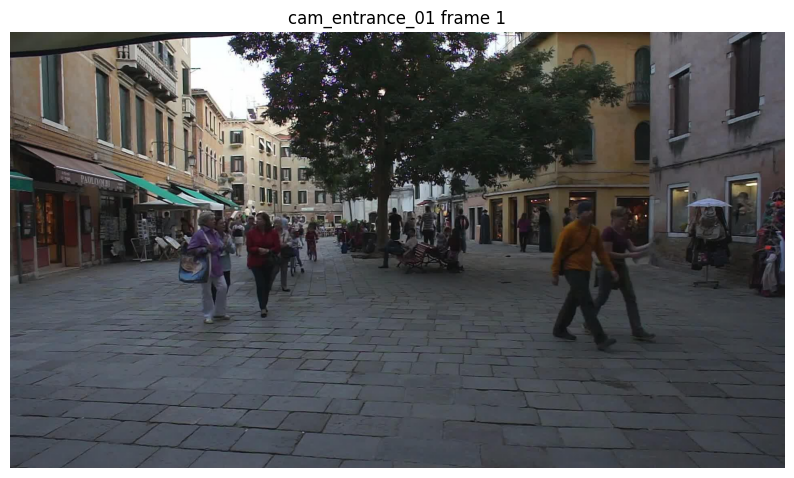

In [6]:
# Cell này thực hiện một bước cụ thể trong luồng pipeline, có thể là nạp dữ liệu, xử lý, hoặc lưu kết quả.
import cv2
import matplotlib.pyplot as plt

sample = frame_index_df.iloc[0]
img = cv2.imread(sample["image_path"])
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 6))
plt.imshow(img_rgb)
plt.title(f'{sample["camera_id"]} frame {sample["frame_id"]}')
plt.axis("off")
plt.show()
